# # 01 - Data acquisition & exploratory data analysis
Dataset: UCI Heart Disease, Cleveland subset (303 patients, 13 features + diagnosis).
The download step tries the UCI repository first and falls back to a GitHub mirror, recoding it back to the original UCI coding.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 140)

# ## 1. Acquire and clean

In [2]:
from heart.data import download, load_raw, clean
raw = load_raw(download())
print(raw.shape); raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
2,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
3,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
4,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0


In [3]:
print("Missing values in raw file ('?' markers):"); print(raw.isna().sum()[lambda s: s > 0])
print("\nDiagnosis (num) distribution:", raw["num"].value_counts().sort_index().to_dict())

Missing values in raw file ('?' markers):
ca      5
thal    2
dtype: int64

Diagnosis (num) distribution: {0: 165, 1: 138}


In [4]:
df = clean(raw)
print(df.shape, "| duplicates removed:", len(raw) - len(df))
df.describe().T.round(2)

(302, 14) | duplicates removed: 1


,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
cp,302.0,3.16,0.96,1.0,3.00,3.0,4.00,4.0
trestbps,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.99,0.99,0.0,0.00,0.5,2.00,2.0
thalach,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2


# **Cleaning decisions**
* `num` (0-4) is binarised: 0 = no disease, 1-4 = disease. This is the standard framing and gives a near-balanced target.
* `ca` and `thal` have a handful of missing values. They are **kept as NaN** and imputed *inside* the model pipeline (median / most frequent), so the identical logic runs at training and serving time and no information leaks from the test split.
* Out-of-range codes and physiologically impossible values (cholesterol or BP of 0) are set to NaN instead of dropping rows.

# ## 2. Visual exploration

In [5]:
from heart import eda
paths = eda.run_all(df)
for p in paths: print(p.name)

class_balance.png
missing_values.png
numeric_histograms.png
numeric_boxplots.png
categorical_rates.png
correlation_heatmap.png
target_correlation.png


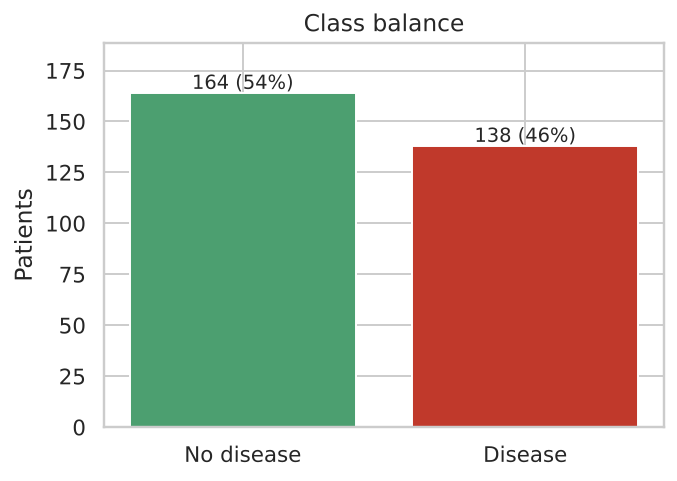

In [6]:
display(Image('reports/figures/class_balance.png', width=420))

# The classes are close to balanced (~54% / 46%), so accuracy is meaningful, but we still report precision, recall and ROC-AUC and use stratified splits.

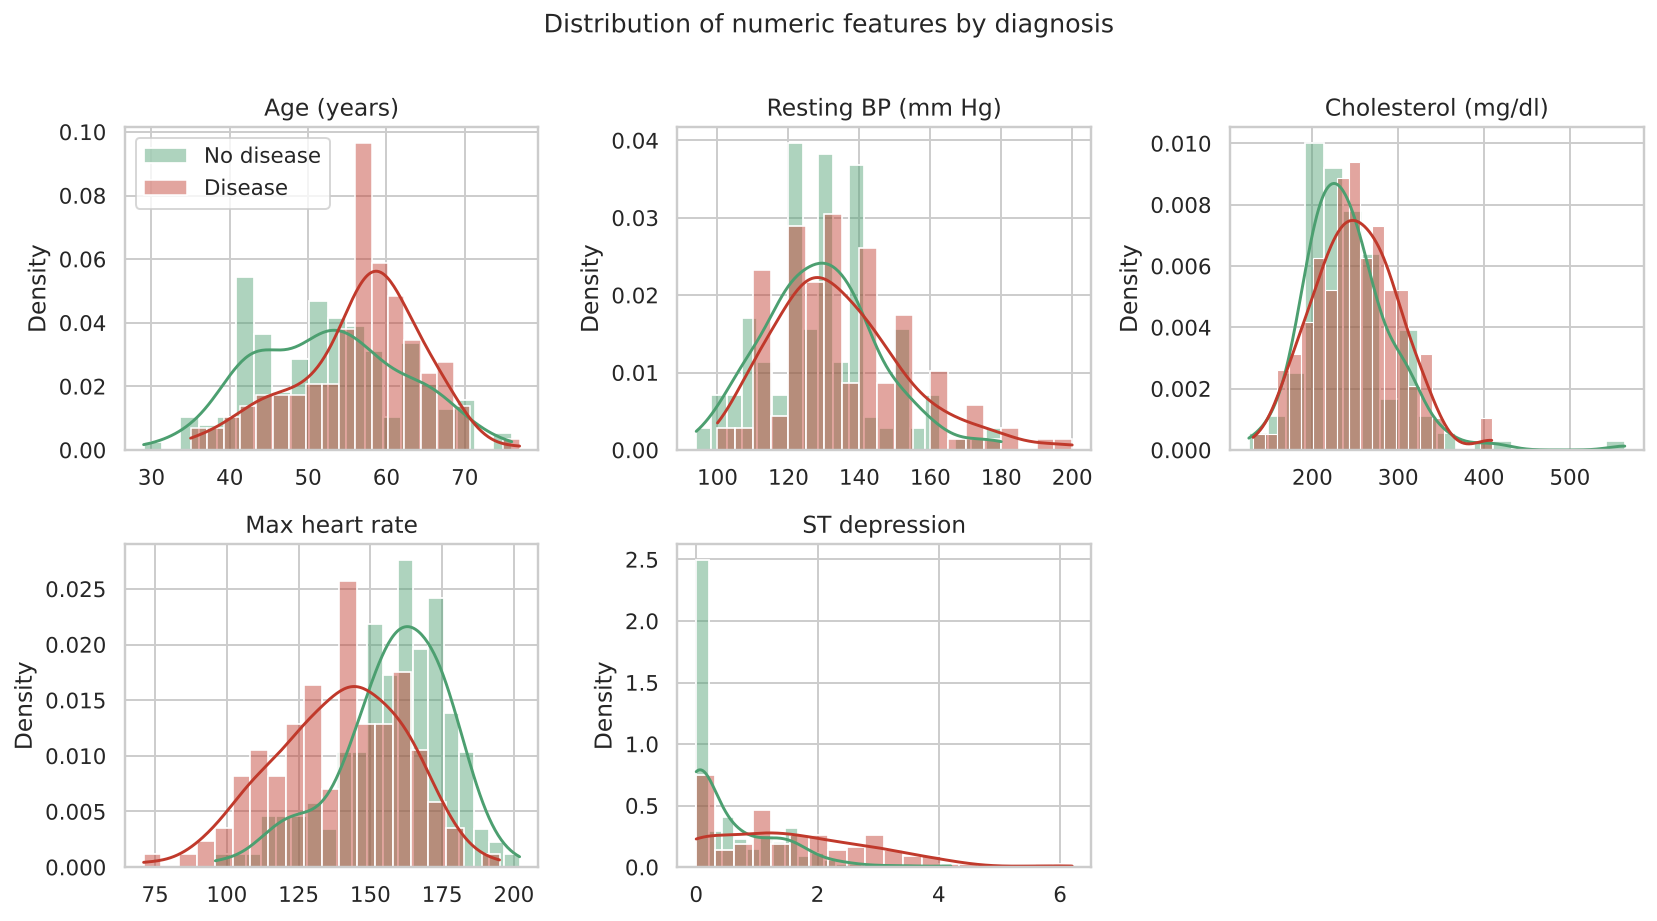

In [7]:
display(Image('reports/figures/numeric_histograms.png'))

# Max heart rate (`thalach`) is clearly lower in patients with disease, and ST depression (`oldpeak`) is higher. Cholesterol and resting BP overlap heavily between classes, so they will carry little signal on their own.

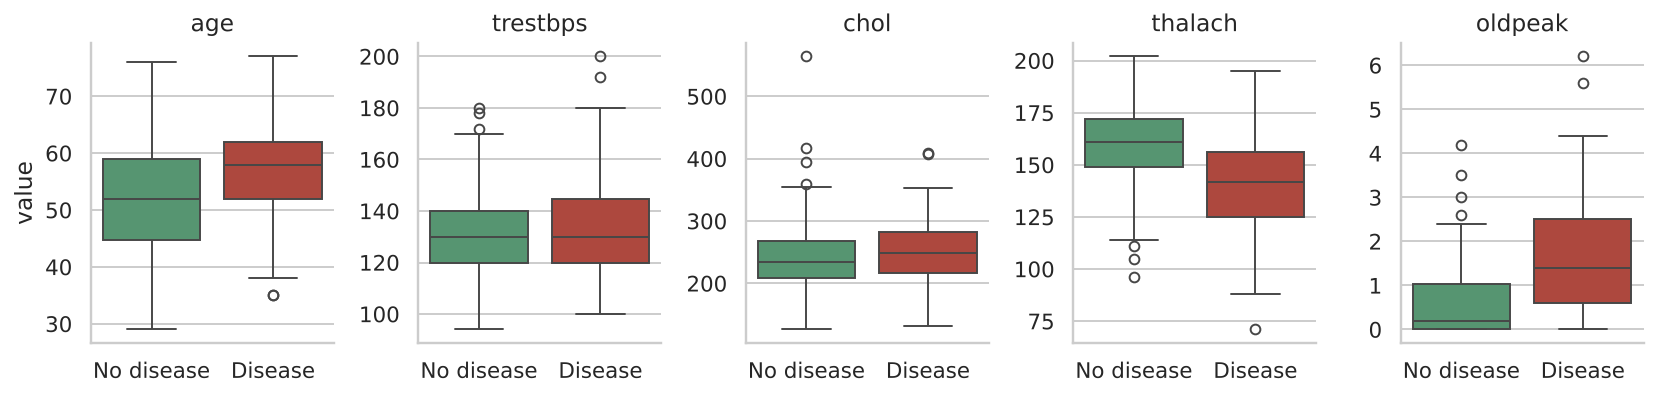

In [8]:
display(Image('reports/figures/numeric_boxplots.png'))

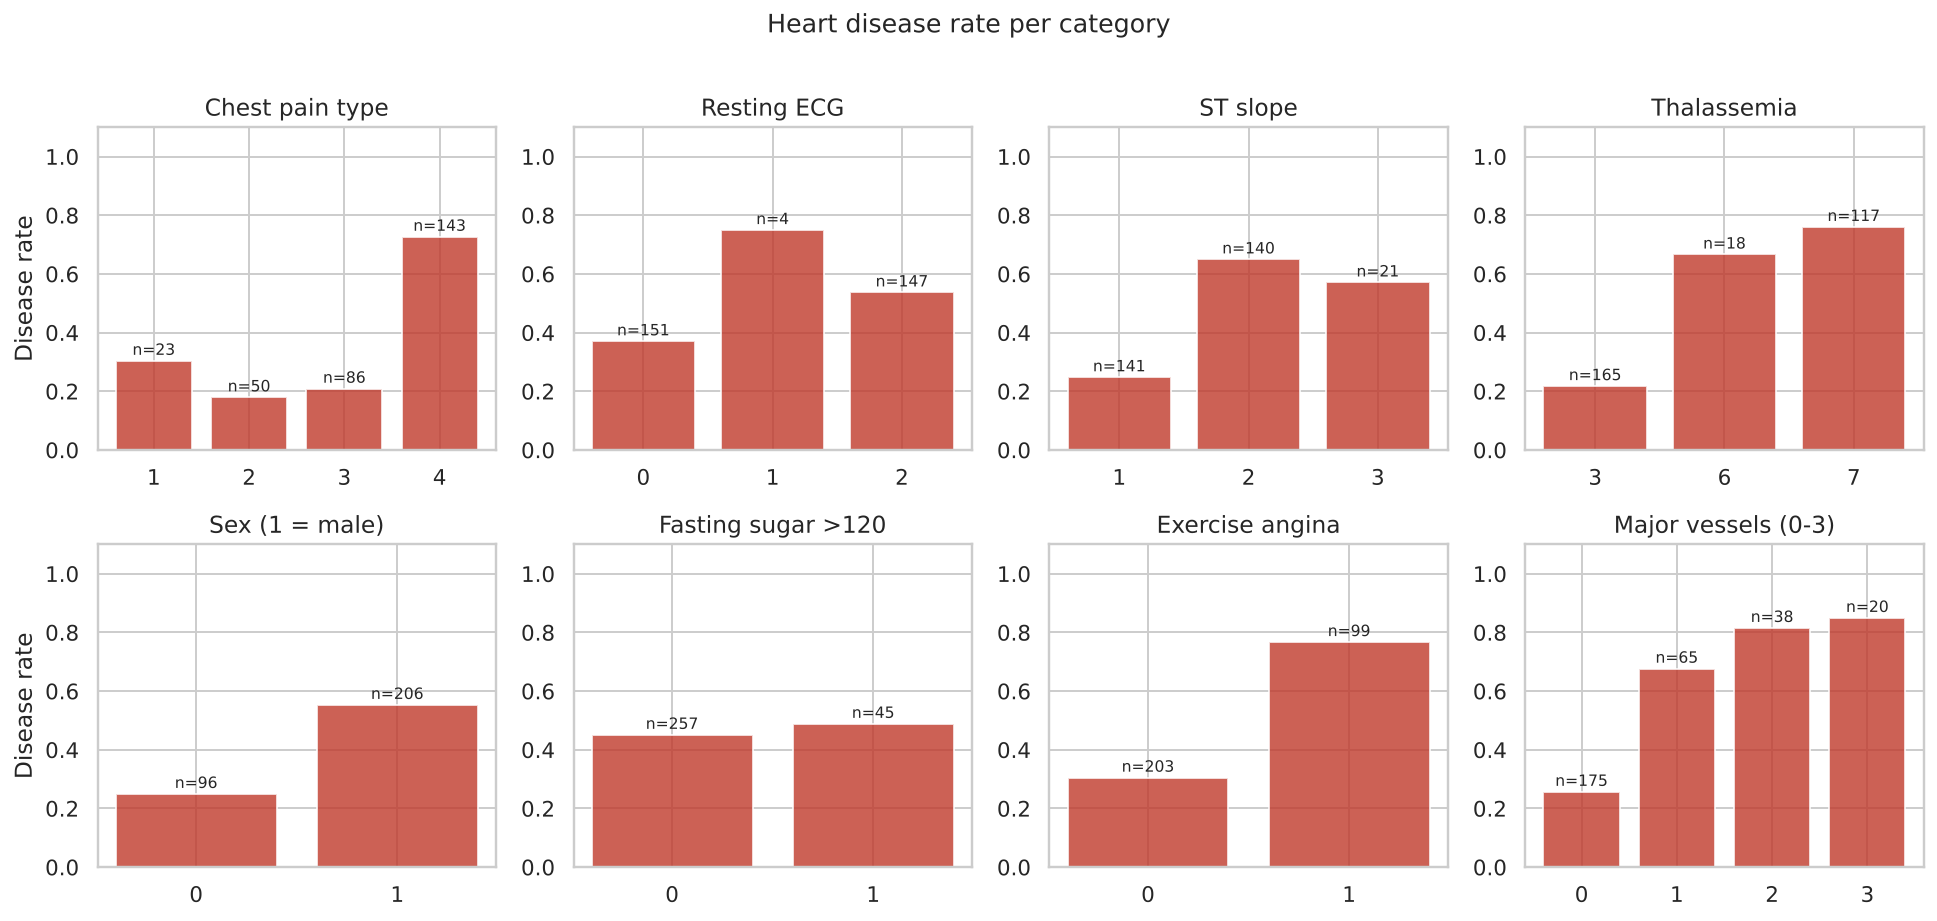

In [9]:
display(Image('reports/figures/categorical_rates.png'))

# Asymptomatic chest pain (cp=4), exercise-induced angina, reversible thalassemia defect (thal=7) and the number of coloured vessels (`ca`) are the strongest categorical markers. `restecg=1` has only 4 patients, so its rate is unreliable. Fasting blood sugar shows almost no difference.

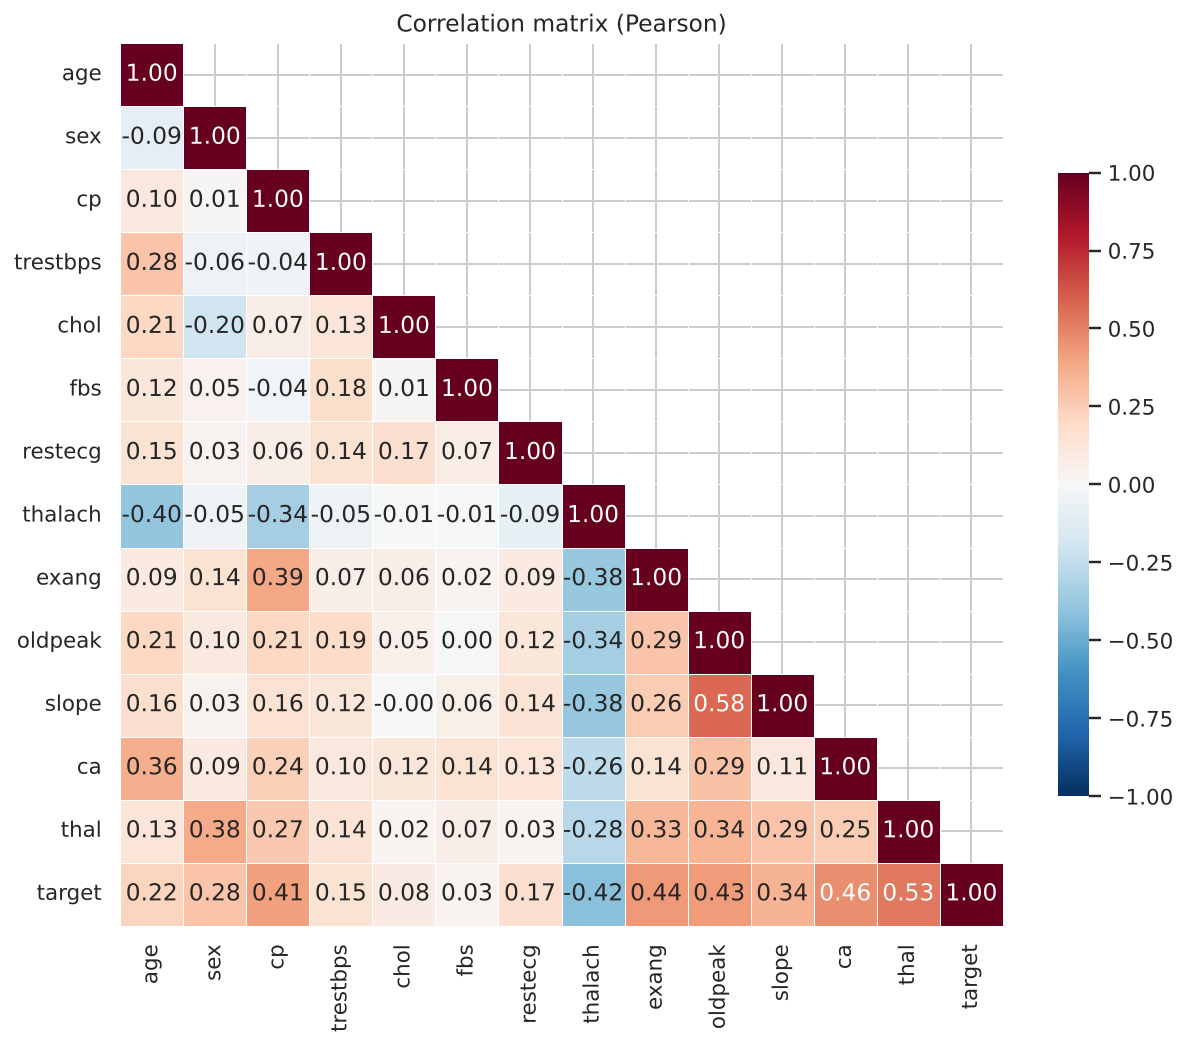

In [10]:
display(Image('reports/figures/correlation_heatmap.png', width=650))

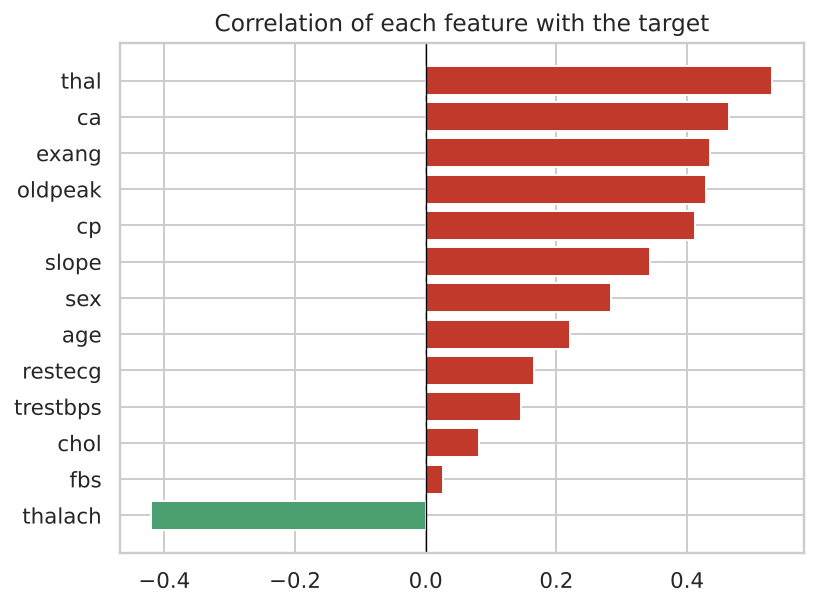

In [11]:
display(Image('reports/figures/target_correlation.png', width=520))

In [12]:
corr = df.corr()["target"].drop("target").sort_values(key=abs, ascending=False)
corr.round(3).to_frame("corr_with_target")

,corr_with_target
thal,0.531
ca,0.464
exang,0.436
oldpeak,0.429
thalach,-0.420
cp,0.413
slope,0.344
sex,0.284
age,0.221
restecg,0.166


# **Takeaways for modelling**
* No pair of features is highly collinear (|r| < 0.6), so all 13 features are kept.
* `cp`, `restecg`, `slope`, `thal` are nominal codes, so they are one-hot encoded rather than treated as numbers.
* Numeric features have different scales (oldpeak 0-6 vs chol 100-560), so they are standardised. This matters for Logistic Regression, SVM and KNN.
* Small dataset (302 rows) means CV variance is high; model choice should account for that.

In [13]:
from heart.config import CLEAN_PATH
df.to_csv(CLEAN_PATH, index=False); print("saved", CLEAN_PATH)

saved /home/claude/heart-risk-mlops/data/processed/heart_clean.csv
